# 21 — Valutazione della classificazione delle squadre (ground truth sulle annotazioni di E3)

**Obiettivo.** Misurare la *correttezza* (non solo la coerenza) della classificazione delle squadre del notebook 13, usando i punti già annotati per E3 (176 punti annotabili su 40 fotogrammi delle 7 clip NBA).

**Protocollo (fissato prima di vedere i risultati)**
1. **Fase 1 – Etichette.** Il notebook genera, per ogni clip, un foglio con un ritaglio per ciascun punto annotato e un file `team_labels_template.csv` (una riga per punto). Si compila la colonna `team` con `scura`, `chiara`, `arbitro` oppure `incerto`, guardando **solo i ritagli** (nessuna predizione viene mostrata in questa fase), e si salva come `annotations/team_labels.csv`.
2. **Fase 2 – Valutazione.** Classificazione delle squadre con **lo stesso metodo e gli stessi parametri del notebook 13** (Lab sul busto, K-means k=2 sulla mediana per traccia, squadra 0 = maglia più scura, divisione dopo 5 campioni del colore opposto, tracce anomale escluse). Nessun parametro viene modificato dopo aver visto i risultati.
3. **Associazione.** Stesso *matching* di E3 (algoritmo ungherese per fotogramma, distanza massima 80 px tra punto annotato e punto a terra della traccia).

**Metriche:** accuratezza sui giocatori associati (con intervallo di Wilson al 95%), giocatori esclusi per errore, arbitri esclusi correttamente, correttezza per traccia e tracce che mescolano le due squadre.

**Sorgente delle tracce:** SAM2 + ri-detection (`redet`, notebook 09), come in E3. Il metodo di classificazione è lo stesso usato con BoT-SORT nel modulo eventi.

In [5]:
# ==== SETUP COMUNE (uguale in tutti i notebook) ====
import sys, os
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/Tesi_Basket')
else:
    ROOT = Path(os.environ.get('TESI_ROOT', r'F:\Tesi Basket'))
assert ROOT.is_dir(), f'Cartella del progetto non trovata: {ROOT}'
print('Progetto:', ROOT)

import json, hashlib
from datetime import datetime
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
try:
    from IPython.display import display
except ImportError:
    display = print

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Progetto: /content/drive/MyDrive/Tesi_Basket


## 1. Configurazione (congelata: stessi valori del notebook 13 e di E3)

In [ ]:
VARIANT = 'redet'                       # tracce SAM2 + ri-detection, come in E3
MANIFEST = ROOT / 'annotations' / f'manifest_sam2_{VARIANT}.csv'
ANNOT = ROOT / 'annotations' / 'annotations.csv'
TEAM_LABELS = ROOT / 'annotations' / 'team_labels.csv'      # da compilare nella fase 1
VIDEO_DIR = ROOT / 'videos'

GATE_PX = 80.0            # come E3
INTERP_MAX_GAP = 20       # come notebook 13
DUP_IOU = 0.7
SPLIT_ON_TEAM_CHANGE = True
SPLIT_MIN_SAMPLES = 5
OUTLIER_K = 3.0
CONFIG = dict(variant=VARIANT, gate_px=GATE_PX, interp_max_gap=INTERP_MAX_GAP, dup_iou=DUP_IOU,
              split_on_team_change=SPLIT_ON_TEAM_CHANGE, split_min_samples=SPLIT_MIN_SAMPLES, outlier_k=OUTLIER_K)

RUN = ROOT / 'experiments' / 'verifica_squadre' / ('run_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
RUN.mkdir(parents=True, exist_ok=False); FIG = RUN / 'figure'; FIG.mkdir()
print('Output di questa esecuzione:', RUN)

man = pd.read_csv(MANIFEST).fillna('')
gt_all = pd.read_csv(ANNOT, dtype={'player_id': str})
gt = gt_all[gt_all.annotatable.eq(1)].dropna(subset=['x_px', 'y_px']).copy()
gt['frame'] = gt.frame.astype(int)
print(f'Punti annotabili: {len(gt)} | clip: {gt.clip_id.nunique()}')

def video_path(clip_id):
    row = man[man.clip_id.eq(clip_id)]
    if len(row) and 'video' in man.columns and row.video.iloc[0]:
        p = ROOT / row.video.iloc[0]
        if p.is_file(): return p
    for ext in ['.mov', '.mp4', '.mkv', '.avi']:
        p = VIDEO_DIR / f'{clip_id}{ext}'
        if p.is_file(): return p
    raise FileNotFoundError(f'Video di {clip_id} non trovato in {VIDEO_DIR}')

def read_frames(path):
    cap = cv2.VideoCapture(str(path)); out = []
    while True:
        ok, f = cap.read()
        if not ok: break
        out.append(f)
    fps = cap.get(cv2.CAP_PROP_FPS); cap.release()
    return out, fps

Output di questa esecuzione: /content/drive/MyDrive/Tesi_Basket/experiments/E5_squadre/run_20261119_103710
Punti annotabili: 176 | clip: 7


## 2. Fase 1 — fogli per l'etichettatura (nessuna predizione mostrata)

Un ritaglio **per ogni punto annotato** (`clip_id`, `frame`, `player_id`): in E3 lo stesso `player_id` può indicare persone diverse dopo un cambio di inquadratura, per cui si etichetta il singolo punto. Il punto giallo indica i piedi del giocatore da etichettare. Compilare `team` con: `scura`, `chiara`, `arbitro`, `incerto`.

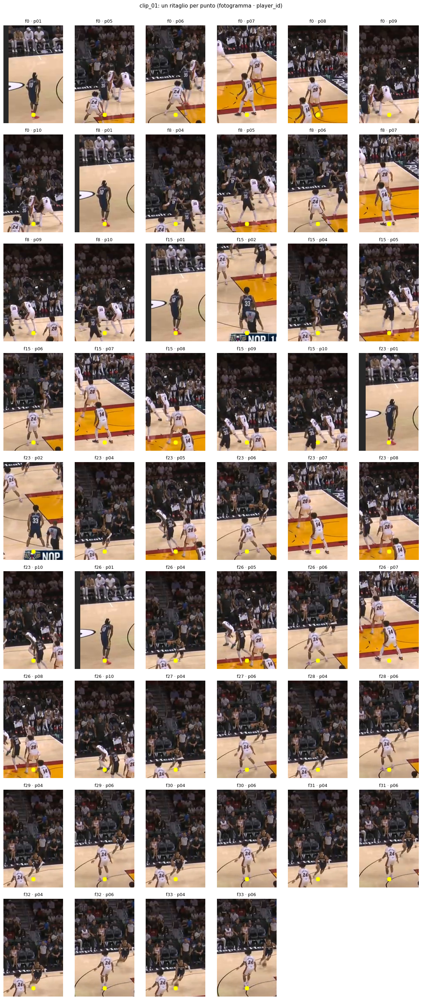

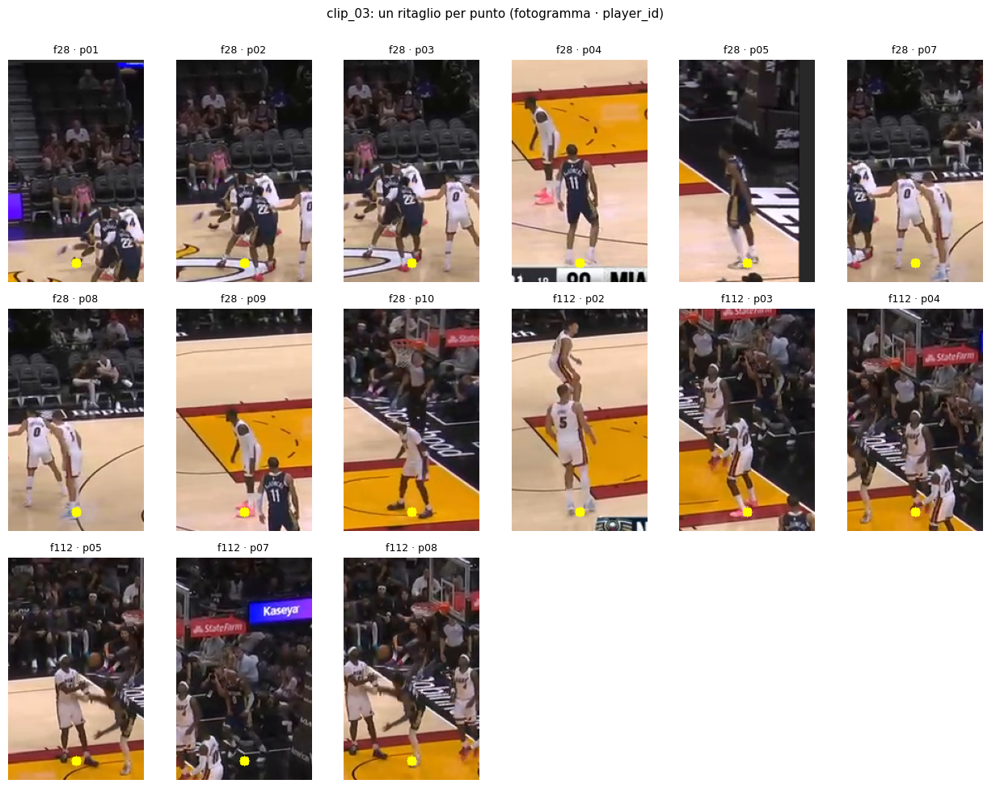

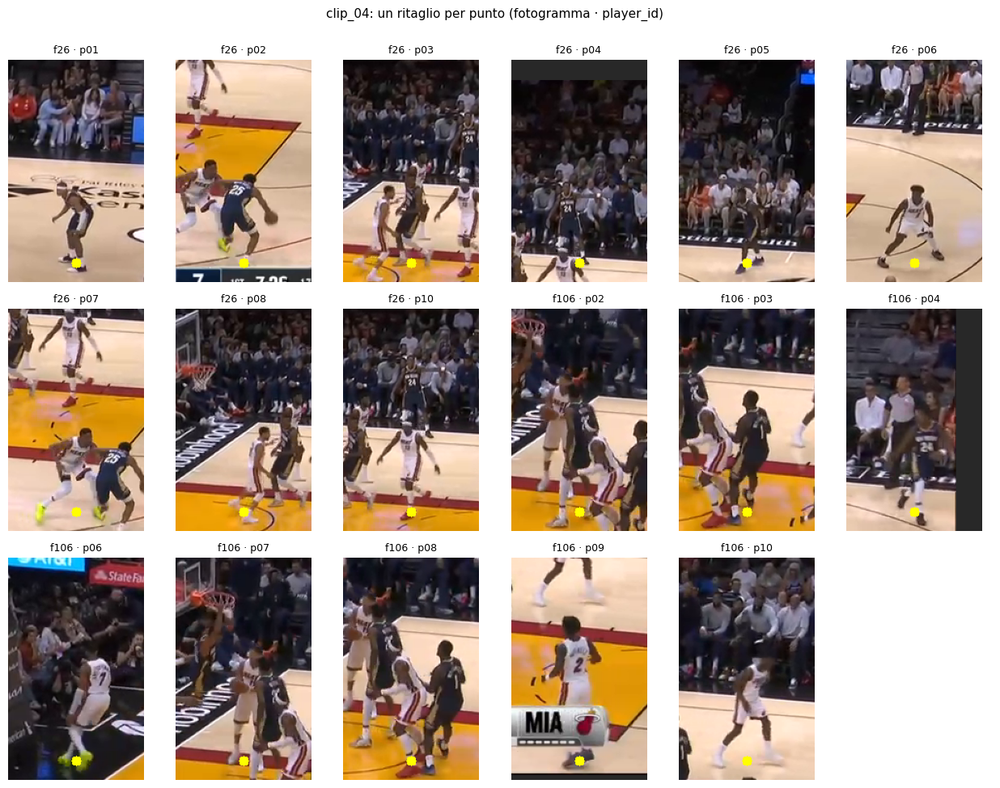

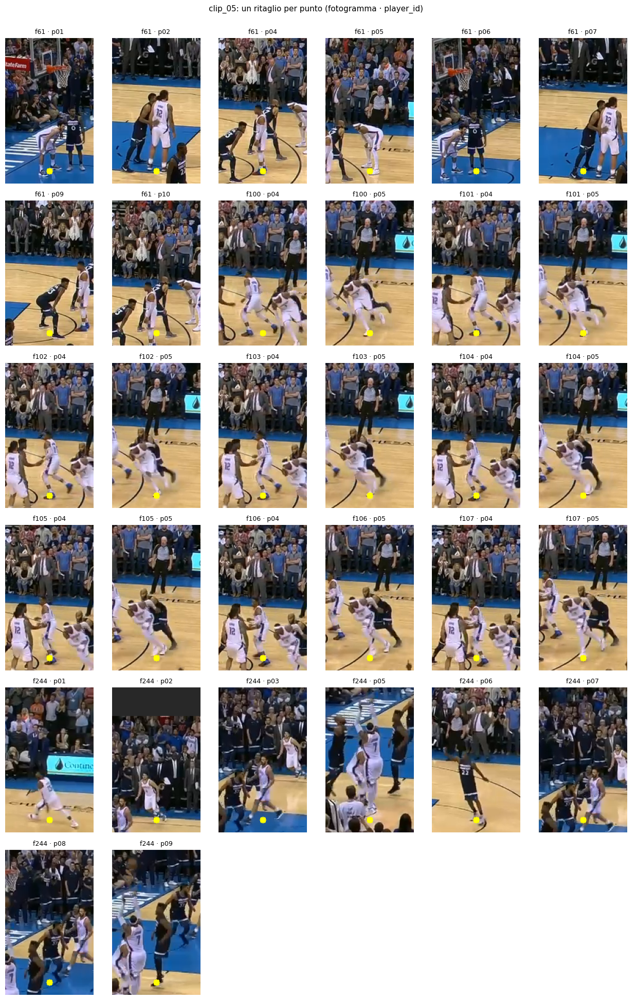

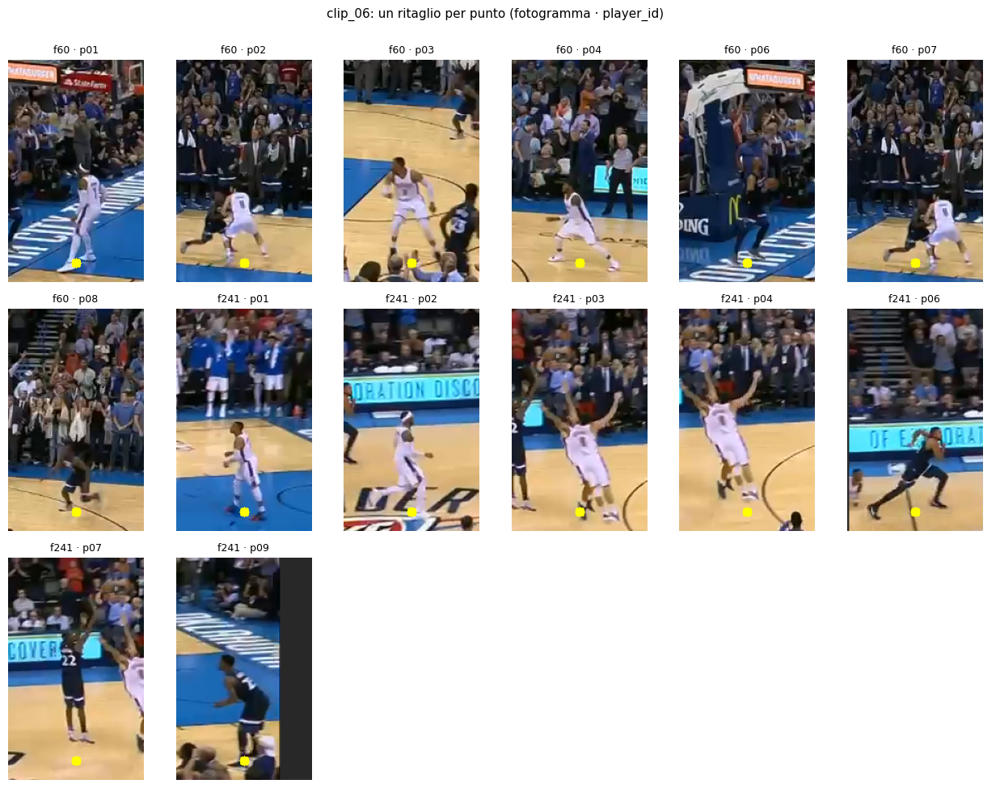

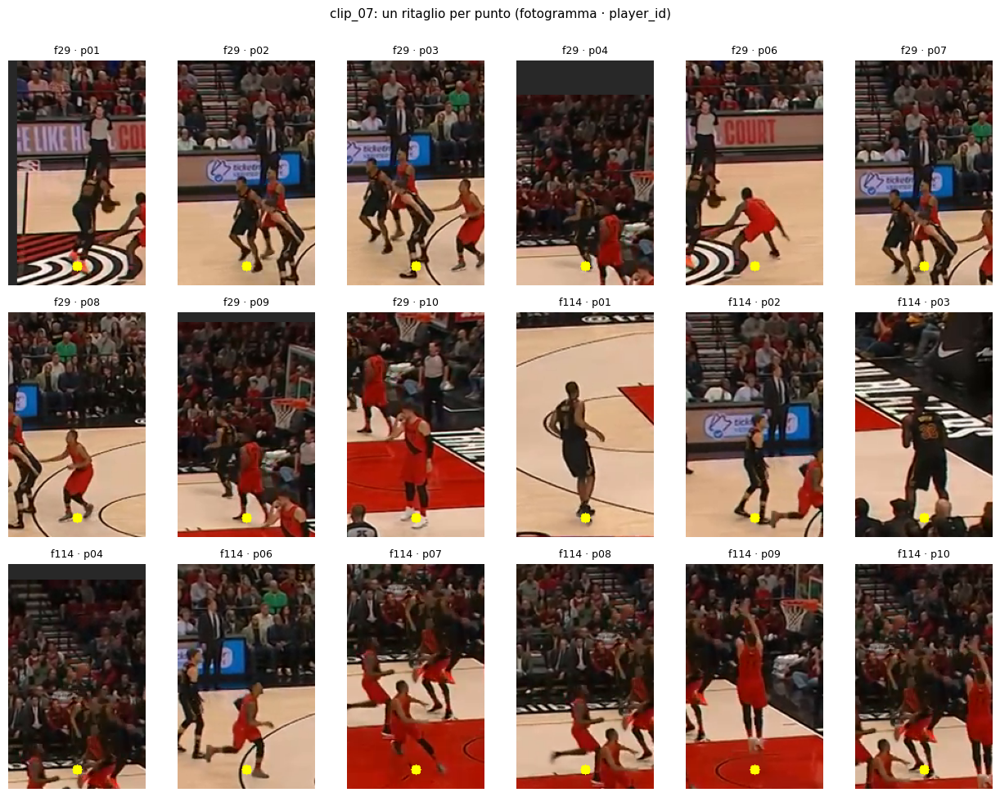

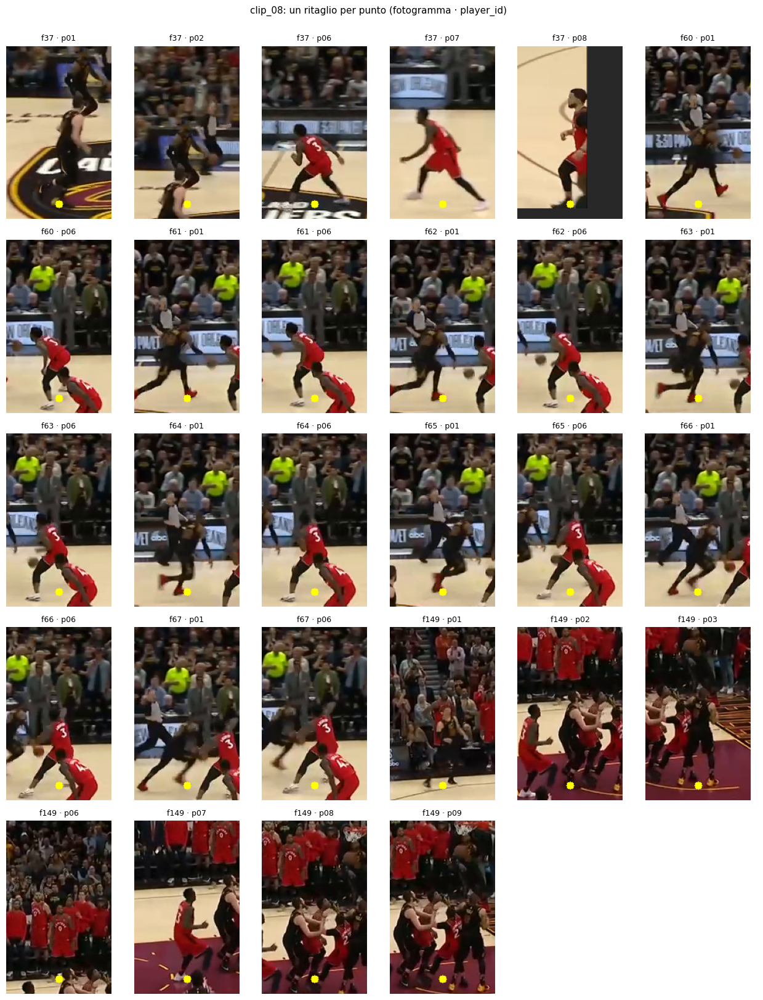

176 punti da etichettare. Template: /content/drive/MyDrive/Tesi_Basket/experiments/E5_squadre/run_20261119_103710/team_labels_template.csv
Compilarlo (scura / chiara / arbitro / incerto) e salvarlo come /content/drive/MyDrive/Tesi_Basket/annotations/team_labels.csv


In [7]:
CROP_W, CROP_H = 140, 230    # solo per la visualizzazione: non influisce sulla valutazione
NCOL = 6

def crop_around(img, x, y):
    x1, x2 = int(x - CROP_W / 2), int(x + CROP_W / 2); y1, y2 = int(y - CROP_H + 20), int(y + 20)
    pad = cv2.copyMakeBorder(img, CROP_H, CROP_H, CROP_W, CROP_W, cv2.BORDER_CONSTANT, value=(40, 40, 40))
    c = pad[y1 + CROP_H:y2 + CROP_H, x1 + CROP_W:x2 + CROP_W].copy()
    cv2.circle(c, (int(x - x1), int(y - y1)), 5, (0, 255, 255), -1)
    return c

template = []
for clip_id, g in gt.groupby('clip_id'):
    frames, _ = read_frames(video_path(clip_id))
    g = g.sort_values(['frame', 'player_id']).reset_index(drop=True)
    nrow = int(np.ceil(len(g) / NCOL))
    fig, axes = plt.subplots(nrow, NCOL, figsize=(2.1 * NCOL, 3.3 * nrow), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for k, r in g.iterrows():
        ax = axes.ravel()[k]
        ax.imshow(cv2.cvtColor(crop_around(frames[int(r.frame)], r.x_px, r.y_px), cv2.COLOR_BGR2RGB))
        ax.set_title(f'f{int(r.frame)} · {r.player_id}', fontsize=9)
        template.append(dict(clip_id=clip_id, frame=int(r.frame), player_id=r.player_id, team=''))
    fig.suptitle(f'{clip_id}: un ritaglio per punto (fotogramma · player_id)', fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    fig.savefig(RUN / f'etichette_{clip_id}.png', dpi=110); plt.show(); plt.close(fig)

template = pd.DataFrame(template)
template.to_csv(RUN / 'team_labels_template.csv', index=False)
print(f'{len(template)} punti da etichettare. Template:', RUN / 'team_labels_template.csv')
print('Compilarlo (scura / chiara / arbitro / incerto) e salvarlo come', TEAM_LABELS)

## 3. Controllo delle etichette (la valutazione parte solo se il file è completo)

In [8]:
VALID = {'scura', 'chiara', 'arbitro', 'incerto'}
if not TEAM_LABELS.is_file():
    raise SystemExit(f'Fase 1 completata. Compilare {TEAM_LABELS.name} e rieseguire il notebook dalla sezione 3.')
labels = pd.read_csv(TEAM_LABELS, dtype={'player_id': str}, sep=None, engine='python').fillna('')
labels['team'] = labels.team.str.strip().str.lower()
bad = labels[~labels.team.isin(VALID)]
assert bad.empty, f'Valori non validi in team: {bad[["clip_id","player_id","team"]].values.tolist()}'
KEY = ['clip_id', 'frame', 'player_id']
labels['frame'] = labels.frame.astype(int)
assert not labels.duplicated(KEY).any(), 'Etichette duplicate'
missing = gt[KEY].merge(labels, how='left', on=KEY)
assert missing.team.notna().all(), 'Punti senza etichetta: ' + str(missing[missing.team.isna()][KEY].values.tolist())
gt_t = gt.merge(labels[KEY + ['team']], on=KEY, how='left').rename(columns={'team': 'gt_team'})
print(gt_t.gt_team.value_counts().to_dict())
# Nota: 'scura'/'chiara' sono relative alla clip; la squadra 0 del metodo è per costruzione la maglia più scura.

{'chiara': 102, 'scura': 74}


## 4. Fase 2 — classificazione delle squadre (codice del notebook 13, parametri invariati)
Per le tracce SAM2 il notebook 13 non usa la classe *referee* del detector: gli arbitri sono esclusi solo se il loro colore è lontano da entrambe le squadre.

In [9]:
def interpolate(t, max_gap):
    out = []
    for tid, g in t.groupby('track_id'):
        g = g.set_index('frame').reindex(range(g.frame.min(), g.frame.max() + 1))
        miss = g.x1.isna(); run = (miss != miss.shift()).cumsum()
        g = g.interpolate(limit_area='inside')[~miss | (miss.groupby(run).transform('sum') <= max_gap)]
        g['track_id'] = tid; out.append(g.reset_index().rename(columns={'index': 'frame'}))
    return pd.concat(out, ignore_index=True)

def iou_xyxy(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    ar = lambda r: (r[:, 2] - r[:, 0]) * (r[:, 3] - r[:, 1])
    return inter / (ar(a)[:, None] + ar(b)[None, :] - inter + 1e-9)

class KMeans2:
    def __init__(self, n_init=20, iters=100, seed=0): self.n_init, self.iters, self.rng = n_init, iters, np.random.default_rng(seed)
    def fit(self, X):
        X = np.asarray(X, np.float64); best = None
        for _ in range(self.n_init):
            C = X[self.rng.choice(len(X), 2, replace=len(X) < 2)].copy()
            for _ in range(self.iters):
                lab = self._assign(X, C)
                newC = np.array([X[lab == k].mean(0) if (lab == k).any() else C[k] for k in range(2)])
                if np.allclose(newC, C): break
                C = newC
            inertia = ((X - C[self._assign(X, C)]) ** 2).sum()
            if best is None or inertia < best[0]: best = (inertia, C)
        self.cluster_centers_ = best[1]; return self
    @staticmethod
    def _assign(X, C): return np.argmin(((X[:, None, :] - C[None]) ** 2).sum(-1), axis=1)
    def predict(self, X): return self._assign(np.asarray(X, np.float64), self.cluster_centers_)

def classify_clip(frames, tracks):
    H_IMG, W_IMG = frames[0].shape[:2]
    smp = np.concatenate([cv2.cvtColor(np.ascontiguousarray(f[int(.6*H_IMG):int(.78*H_IMG), int(.2*W_IMG):int(.8*W_IMG)]),
                                       cv2.COLOR_BGR2LAB).reshape(-1, 3) for f in frames[::30]]).astype(np.float32)
    COURT_LAB = np.median(smp, axis=0)

    def jersey_feature(img, b):
        x1, y1, x2, y2 = map(int, b)
        x1, x2 = max(0, x1), min(W_IMG, x2); y1, y2 = max(0, y1), min(H_IMG, y2)
        w, h = x2 - x1, y2 - y1
        if h < 30 or w < 8: return None
        crop = np.ascontiguousarray(img[y1 + int(.15*h):y1 + int(.5*h), x1 + int(.2*w):x2 - int(.2*w)])
        if crop.size == 0 or crop.ndim != 3: return None
        lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).reshape(-1, 3).astype(np.float32)
        lab = lab[np.linalg.norm(lab - COURT_LAB, axis=1) > 25]
        if len(lab) < 20: return None
        hist = np.histogramdd(lab, bins=(4, 6, 6), range=((0, 256), (0, 256), (0, 256)))[0].ravel()
        return hist / hist.sum()

    def sample_features(t):
        F, K, R = [], [], []
        for r in t[t.frame % 3 == 0].itertuples():
            f = jersey_feature(frames[int(r.frame)], (r.x1, r.y1, r.x2, r.y2))
            if f is not None: F.append(f); K.append(r.track_id); R.append(r.frame)
        return np.array(F), np.array(K), np.array(R)

    def fit_teams(F, K):
        med = {int(t): np.median(F[K == t], axis=0) for t in np.unique(K)}
        n = pd.Series(K).value_counts()
        fit_ids = [t for t in med if n[t] >= 5] or list(med)
        outliers = set()
        for _ in range(2):
            km = KMeans2().fit(np.array([med[t] for t in fit_ids if t not in outliers]))
            lum = [(c.reshape(4, 6, 6).sum((1, 2)) * np.array([32, 96, 160, 224])).sum() for c in km.cluster_centers_]
            if lum[0] > lum[1]: km.cluster_centers_ = km.cluster_centers_[::-1].copy()   # squadra 0 = maglia scura
            team = {t: int(km.predict(med[t][None])[0]) for t in med}
            d = pd.Series({t: np.linalg.norm(med[t] - km.cluster_centers_[team[t]]) for t in med})
            dl = d[[t for t in fit_ids if t not in outliers]]
            thr = dl.median() + OUTLIER_K * max((dl - dl.median()).abs().median() * 1.4826, 0.25 * dl.median(), 1e-6)
            outliers |= set(d.index[d > thr])
        for t in outliers: team[t] = -1
        return km, team

    feats, keys, fr = sample_features(tracks)
    km, team_of = fit_teams(feats, keys)
    n_split = 0
    if SPLIT_ON_TEAM_CHANGE:
        lab_s = km.predict(feats); next_id = int(tracks.track_id.max()) + 1
        for tid in np.unique(keys):
            if team_of[int(tid)] < 0: continue
            sel = np.argsort(fr[keys == tid]); f_t = fr[keys == tid][sel]; l_t = lab_s[keys == tid][sel]
            other = l_t != team_of[int(tid)]
            run_start, cnt, cuts = None, 0, []
            for k, o in enumerate(other):
                if o: run_start = k if cnt == 0 else run_start; cnt += 1
                else:
                    if cnt >= SPLIT_MIN_SAMPLES: cuts.append((f_t[run_start], f_t[k]))
                    cnt = 0
            if cnt >= SPLIT_MIN_SAMPLES: cuts.append((f_t[run_start], tracks.frame.max() + 1))
            for a, b in cuts:
                m = (tracks.track_id == tid) & (tracks.frame >= a) & (tracks.frame < b)
                tracks.loc[m, 'track_id'] = next_id; next_id += 1; n_split += 1
        if n_split:
            feats, keys, fr = sample_features(tracks)
            km, team_of = fit_teams(feats, keys)
    lab_s = km.predict(feats)
    purity = pd.Series({t: (lab_s[keys == t] == team_of[int(t)]).mean() for t in np.unique(keys) if team_of[int(t)] >= 0})
    tracks['team'] = tracks.track_id.map(team_of).fillna(-1).astype(int)   # tracce senza campioni validi -> -1
    return tracks, dict(n_split=n_split, coerenza=float(purity.mean()) if len(purity) else np.nan,
                        tracce=int(tracks.track_id.nunique()))

PRED, info = {}, []
for r in man.itertuples():
    if r.clip_id not in set(gt_t.clip_id) or not r.tracks_csv: continue
    frames, fps = read_frames(video_path(r.clip_id))
    t = pd.read_csv(ROOT / r.tracks_csv)
    if 'mask_area_px' in t: t = t[t.mask_area_px > 0]
    t = t.dropna(subset=['x1', 'y1', 'x2', 'y2'])[['frame', 'track_id', 'x1', 'y1', 'x2', 'y2']].astype({'frame': int, 'track_id': int})
    t = interpolate(t.reset_index(drop=True), INTERP_MAX_GAP)
    t['frame'] = t.frame.astype(int); t['track_id'] = t.track_id.astype(int)
    length = t.groupby('track_id').size(); drop = []
    for fi, g in t.groupby('frame'):
        if len(g) < 2: continue
        M = iou_xyxy(g[['x1','y1','x2','y2']].values, g[['x1','y1','x2','y2']].values); np.fill_diagonal(M, 0)
        ids, idx = g.track_id.values, g.index.values
        for i, j in zip(*np.where(np.triu(M) > DUP_IOU)):
            drop.append(idx[i] if length[ids[i]] < length[ids[j]] else idx[j])
    t = t.drop(index=sorted(set(drop))).reset_index(drop=True)
    t, inf = classify_clip(frames, t)
    t['foot_x'] = (t.x1 + t.x2) / 2; t['foot_y'] = t.y2
    PRED[r.clip_id] = t
    info.append(dict(clip_id=r.clip_id, split=r.split, **inf))
    t.to_csv(RUN / f'{r.clip_id}_tracce_squadre.csv', index=False)
info = pd.DataFrame(info); display(info)

,clip_id,split,n_split,coerenza,tracce
0,clip_01,validation,2,0.930710,12
1,clip_03,validation,0,0.965758,11
2,clip_04,test,3,0.907439,13
3,clip_05,test,2,0.972807,14
4,clip_06,test,0,0.971787,13
5,clip_07,validation,1,0.922714,10
6,clip_08,test,0,0.920924,9


## 5. Associazione con le annotazioni (stesso matching di E3)

In [10]:
def match_annotations(gt, pred, gate):
    rows = []
    for frame, g in gt.groupby('frame'):
        p = pred[pred.frame.eq(frame)].dropna(subset=['foot_x', 'foot_y']).reset_index(drop=True)
        g = g.reset_index(drop=True); matched = {}
        if len(g) and len(p):
            dist = np.linalg.norm(g[['x_px', 'y_px']].to_numpy()[:, None] - p[['foot_x', 'foot_y']].to_numpy()[None], axis=2)
            cost = np.where(dist <= gate, dist, (len(g) + len(p) + 1) * (gate + 1))
            aa, bb = linear_sum_assignment(cost)
            matched = {int(a): (int(p.iloc[b].track_id), int(p.iloc[b].team), float(dist[a, b])) for a, b in zip(aa, bb) if dist[a, b] <= gate}
        for i, r in g.iterrows():
            tid, team, err = matched.get(i, (None, None, np.nan))
            rows.append({**r.to_dict(), 'pred_id': tid, 'pred_team': team, 'error_px': err})
    return pd.DataFrame(rows)

M = pd.concat([match_annotations(gt_t[gt_t.clip_id.eq(c)], p, GATE_PX).assign(clip_id=c) for c, p in PRED.items()], ignore_index=True)
NAME = {0: 'scura', 1: 'chiara', -1: 'esclusa'}
M['pred_label'] = M.pred_team.map(lambda v: NAME.get(int(v)) if pd.notna(v) else 'non associato')
M.to_csv(RUN / 'matching_squadre.csv', index=False)
print(pd.crosstab(M.gt_team, M.pred_label, margins=True))

pred_label  chiara  non associato  scura  All
gt_team                                      
chiara          82              2     18  102
scura            3              8     63   74
All             85             10     81  176


## 6. Metriche

In [11]:
from math import sqrt
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z*z/n; c = (p + z*z/(2*n)) / d; h = z * sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return (c - h, c + h)

def summary(m):
    pl = m[m.gt_team.isin(['scura', 'chiara']) & m.pred_id.notna()]
    corr = int((pl.pred_label == pl.gt_team).sum()); wrong = int(pl.pred_label.isin(['scura','chiara']).sum() - corr)
    excl = int(pl.pred_label.eq('esclusa').sum()); n = len(pl)
    assigned = pl[pl.pred_label.isin(['scura', 'chiara'])]
    ref = m[m.gt_team.eq('arbitro') & m.pred_id.notna()]
    lo, hi = wilson(corr, n); lo2, hi2 = wilson(int((assigned.pred_label == assigned.gt_team).sum()), len(assigned))
    return dict(giocatori_annotati=int(m.gt_team.isin(['scura','chiara']).sum()), giocatori_associati=n,
                corretti=corr, squadra_opposta=wrong, esclusi_per_errore=excl,
                accuratezza=corr / n if n else np.nan, ic95=f'{lo:.2f}–{hi:.2f}',
                accuratezza_tra_assegnati=len(assigned) and (assigned.pred_label == assigned.gt_team).mean(), ic95_assegnati=f'{lo2:.2f}–{hi2:.2f}',
                arbitri_associati=len(ref), arbitri_esclusi=int(ref.pred_label.eq('esclusa').sum()),
                incerti=int(m.gt_team.eq('incerto').sum()))

tot = pd.DataFrame([summary(M)], index=['totale'])
per_clip = pd.DataFrame({c: summary(g) for c, g in M.groupby('clip_id')}).T
res = pd.concat([per_clip, tot]); res.to_csv(RUN / 'metriche_squadre.csv')
display(res)

# --- livello traccia: ogni traccia associata ad almeno un giocatore annotato ---
pl = M[M.gt_team.isin(['scura', 'chiara']) & M.pred_id.notna()]
tr = (pl.groupby(['clip_id', 'pred_id'])
        .agg(squadra_predetta=('pred_label', 'first'), punti=('gt_team', 'size'),
             squadre_gt=('gt_team', lambda s: '/'.join(sorted(set(s)))),
             gt_maggioranza=('gt_team', lambda s: s.value_counts().idxmax())).reset_index())
tr['corretta'] = tr.squadra_predetta.eq(tr.gt_maggioranza)
tr['mescola_squadre'] = tr.squadre_gt.str.contains('/')
tr.to_csv(RUN / 'tracce_squadre.csv', index=False)
lo, hi = wilson(int(tr.corretta.sum()), len(tr))
print(f'Tracce associate: {len(tr)} | corrette: {int(tr.corretta.sum())} ({tr.corretta.mean():.2f}, IC95 {lo:.2f}–{hi:.2f}) '
      f'| tracce che coprono giocatori di entrambe le squadre: {int(tr.mescola_squadre.sum())}')

,giocatori_annotati,giocatori_associati,corretti,squadra_opposta,esclusi_per_errore,accuratezza,ic95,accuratezza_tra_assegnati,ic95_assegnati,arbitri_associati,arbitri_esclusi,incerti
clip_01,52,51,50,1,0,0.980392,0.90–1.00,0.980392,0.90–1.00,0,0,0
clip_03,15,14,13,1,0,0.928571,0.69–0.99,0.928571,0.69–0.99,0,0,0
clip_04,17,17,15,2,0,0.882353,0.66–0.97,0.882353,0.66–0.97,0,0,0
clip_05,32,32,30,2,0,0.9375,0.80–0.98,0.9375,0.80–0.98,0,0,0
clip_06,14,13,12,1,0,0.923077,0.67–0.99,0.923077,0.67–0.99,0,0,0
clip_07,18,15,14,1,0,0.933333,0.70–0.99,0.933333,0.70–0.99,0,0,0
clip_08,28,24,11,13,0,0.458333,0.28–0.65,0.458333,0.28–0.65,0,0,0
totale,176,166,145,21,0,0.873494,0.81–0.92,0.873494,0.81–0.92,0,0,0


Tracce associate: 64 | corrette: 55 (0.86, IC95 0.75–0.92) | tracce che coprono giocatori di entrambe le squadre: 3


## 7. Esempi di errore (per l'analisi qualitativa)

Punti con squadra errata o esclusi: 21


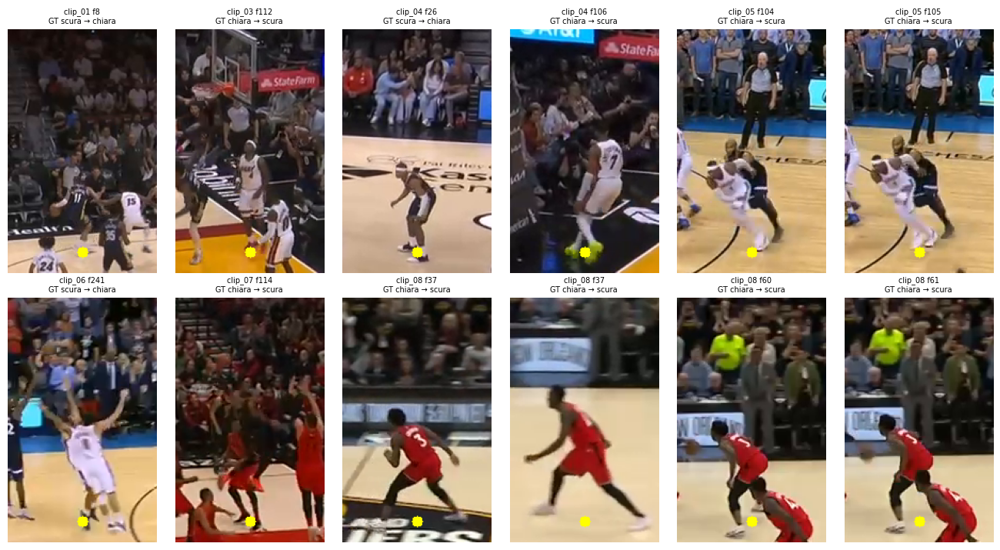

Tutti gli output in /content/drive/MyDrive/Tesi_Basket/experiments/E5_squadre/run_20261119_103710


In [12]:
err = M[M.gt_team.isin(['scura', 'chiara']) & M.pred_id.notna() & (M.pred_label != M.gt_team)]
print(f'Punti con squadra errata o esclusi: {len(err)}')
if len(err):
    show = err.head(12); n = len(show); cols = min(6, n); rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.2 * cols, 3.6 * rows), squeeze=False)
    cache = {}
    for ax in axes.ravel(): ax.axis('off')
    for ax, r in zip(axes.ravel(), show.itertuples()):
        if r.clip_id not in cache: cache[r.clip_id] = read_frames(video_path(r.clip_id))[0]
        ax.imshow(cv2.cvtColor(crop_around(cache[r.clip_id][int(r.frame)], r.x_px, r.y_px), cv2.COLOR_BGR2RGB))
        ax.set_title(f'{r.clip_id} f{int(r.frame)}\nGT {r.gt_team} → {r.pred_label}', fontsize=7)
    fig.tight_layout(); fig.savefig(FIG / 'errori_squadre.png', dpi=150); plt.show()

prov = dict(created=datetime.now().isoformat(), config=CONFIG,
            inputs={p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in [MANIFEST, ANNOT, TEAM_LABELS]})
(RUN / 'provenienza.json').write_text(json.dumps(prov, indent=2))
print('Tutti gli output in', RUN)

## Note per la tesi
- La misura riguarda il **metodo di classificazione** applicato alle tracce SAM2 + ri-detection delle 7 clip; nel modulo eventi lo stesso metodo è applicato alle tracce BoT-SORT, con in più la classe *referee* del detector.
- `scura`/`chiara` sono relative alla singola clip: la corrispondenza con le squadre 0/1 è fissata a priori dall'ordinamento per luminosità.
- Le annotazioni di E3 privilegiano giocatori con il punto a terra visibile: i casi più difficili (occlusioni) sono sotto-rappresentati.
- Riportare sempre i conteggi accanto alle percentuali, con l'intervallo di Wilson.